
=== 2007–2011 ===
Samples: 1050 | MAE: 43.69 | RMSE: 57.20 | R²: 0.971 | MAPE: 0.84%

=== 2011–2019 ===
Samples: 1951 | MAE: 145.21 | RMSE: 186.55 | R²: 0.867 | MAPE: 1.29%

=== 2020–2022 ===
Samples: 746 | MAE: 162.62 | RMSE: 195.22 | R²: 0.956 | MAPE: 0.94%

=== 2022–Latest ===
Samples: 717 | MAE: 97.66 | RMSE: 129.57 | R²: 0.922 | MAPE: 0.39%


=== FINAL COMPARISON ===
    Time Frame  Samples         MAE        RMSE        R2      MAPE
0    2007–2011     1050   43.691259   57.196859  0.971333  0.837200
1    2011–2019     1951  145.209355  186.551641  0.866919  1.285587
2    2020–2022      746  162.621048  195.218481  0.955741  0.935054
3  2022–Latest      717   97.660719  129.571103  0.922370  0.389919


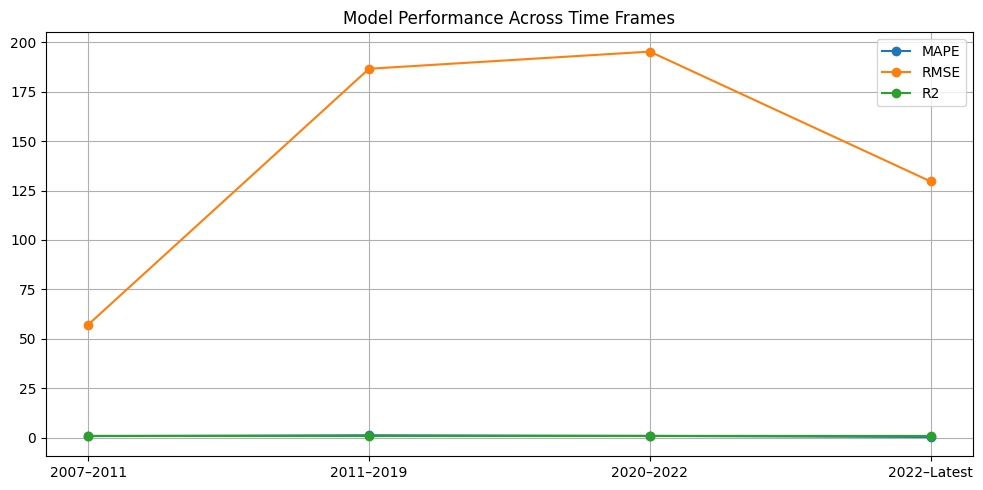

In [1]:
# Research review: Several statistical/neural branches use distinct scaling and split policies. Confirm regime years, transformation fit scope, forecast timing and target-date alignment for each reported score.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# -------------------------------------------------------
# 1) Load and preprocess dataset
# -------------------------------------------------------
df = pd.read_csv("nifty50_2007_to_now.csv")

df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# clean numeric columns
for col in df.columns:
    if col != "Date":
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace(",", "", regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("Date").reset_index(drop=True)
df = df.fillna(method="ffill").fillna(method="bfill")

df = df[["Date", "Open", "High", "Low", "Close"]].dropna()

# -------------------------------------------------------
# 2) Fixed LSTM hyperparameters (your ARO result)
# -------------------------------------------------------
seq_len = 30
units   = 160
dropout = 0.005093563216636045
lr      = 0.002939598205532339
batch_sz= 16
epochs  = int(22.114677099344227)

# -------------------------------------------------------
# 3) Helper functions
# -------------------------------------------------------
def make_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

def build_lstm(seq_len, n_features, units, dropout, lr):
    model = Sequential([
        LSTM(units, activation='tanh', input_shape=(seq_len, n_features)),
        Dropout(dropout),
        Dense(2)  # High + Low
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

def evaluate_period(df_period, label):
    if len(df_period) < seq_len * 3:
        print(f"Skipping {label} — too small.")
        return None

    X_raw = df_period[["Open","High","Low","Close"]].values
    y_raw = df_period[["High","Low"]].values

    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X_raw)
    y_scaled = scaler_y.fit_transform(y_raw)

    # 80% train / 20% test
    n = len(X_scaled)
    train_end = int(n * 0.80)

    X_train_raw, y_train_raw = X_scaled[:train_end], y_scaled[:train_end]
    X_test_raw,  y_test_raw  = X_scaled[train_end:], y_scaled[train_end:]
    dates_test = df_period["Date"].values[train_end:]

    # sequences
    X_train, y_train = make_sequences(X_train_raw, y_train_raw, seq_len)
    X_test,  y_test  = make_sequences(
        np.vstack([X_train_raw[-seq_len:], X_test_raw]),
        np.vstack([y_train_raw[-seq_len:], y_test_raw]),
        seq_len
    )

    model = build_lstm(seq_len, X_train.shape[2], units, dropout, lr)
    cb = [EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]

    model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_sz,
        callbacks=cb,
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0)
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    # metrics
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

    print(f"\n=== {label} ===")
    print(f"Samples: {len(df_period)} | MAE: {mae:.2f} | RMSE: {rmse:.2f} | R²: {r2:.3f} | MAPE: {mape:.2f}%")

    return {
        "Time Frame": label,
        "Samples": len(df_period),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

# -------------------------------------------------------
# 4) EXACT SPLITS YOU REQUESTED
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]

df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]

df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]

df_4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df_1),
    ("2011–2019", df_2),
    ("2020–2022", df_3),
    ("2022–Latest", df_4),
]

# -------------------------------------------------------
# 5) Evaluate all splits
# -------------------------------------------------------
results = []
for label, data_part in splits:
    res = evaluate_period(data_part, label)
    if res:
        results.append(res)

results_df = pd.DataFrame(results)
print("\n\n=== FINAL COMPARISON ===")
print(results_df)

# -------------------------------------------------------
# 6) Comparison plot
# -------------------------------------------------------
plt.figure(figsize=(10,5))
plt.plot(results_df["Time Frame"], results_df["MAPE"], marker="o", label="MAPE")
plt.plot(results_df["Time Frame"], results_df["RMSE"], marker="o", label="RMSE")
plt.plot(results_df["Time Frame"], results_df["R2"], marker="o", label="R2")
plt.grid(True)
plt.legend()
plt.title("Model Performance Across Time Frames")
plt.tight_layout()
plt.show()



=== 2007–2011 ===
Samples: 1050 | MAE: 68.28 | RMSE: 83.24 | R²: 0.940 | MAPE: 1.30%

=== 2011–2019 ===
Samples: 1951 | MAE: 133.69 | RMSE: 167.36 | R²: 0.892 | MAPE: 1.19%

=== 2020–2022 ===
Samples: 746 | MAE: 167.43 | RMSE: 201.49 | R²: 0.953 | MAPE: 0.97%

=== 2022–Latest ===
Samples: 717 | MAE: 136.79 | RMSE: 172.18 | R²: 0.863 | MAPE: 0.55%


=== FINAL COMPARISON ===
    Time Frame  Samples         MAE        RMSE        R2      MAPE
0    2007–2011     1050   68.280179   83.242802  0.939635  1.296214
1    2011–2019     1951  133.686021  167.359073  0.892491  1.186004
2    2020–2022      746  167.425020  201.490830  0.952635  0.973665
3  2022–Latest      717  136.785353  172.176064  0.863192  0.545527


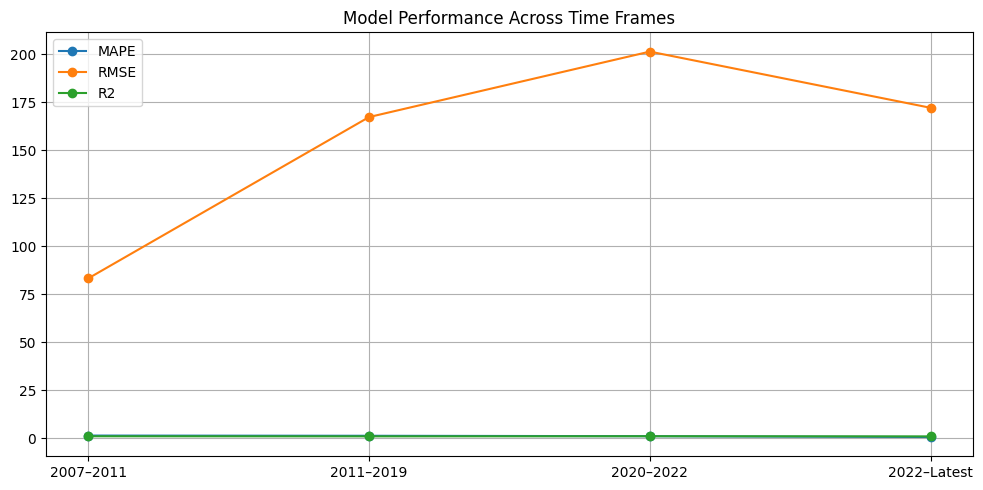

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random, warnings
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# -------------------------------------------------------
# 1) Load and preprocess dataset
# -------------------------------------------------------

df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# clean numeric columns
for col in df.columns:
    if col != "Date":
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace(",", "", regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("Date").reset_index(drop=True)
df = df.fillna(method="ffill").fillna(method="bfill")

df = df[["Date", "Open", "High", "Low", "Close"]].dropna()

# -------------------------------------------------------
# 2) Fixed LSTM hyperparameters (your ARO result)
# -------------------------------------------------------
seq_len = 30
units   = 160
dropout = 0.005093563216636045
lr      = 0.002939598205532339
batch_sz= 16
epochs  = int(22.114677099344227)

# -------------------------------------------------------
# 3) Helper functions
# -------------------------------------------------------
def make_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

def build_lstm(seq_len, n_features, units, dropout, lr):
    model = Sequential([
        LSTM(units, activation='tanh', input_shape=(seq_len, n_features)),
        Dropout(dropout),
        Dense(2)  # High + Low
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

def evaluate_period(df_period, label):
    if len(df_period) < seq_len * 3:
        print(f"Skipping {label} — too small.")
        return None

    X_raw = df_period[["Open","High","Low","Close"]].values
    y_raw = df_period[["High","Low"]].values

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_scaled = scaler_X.fit_transform(X_raw)
    y_scaled = scaler_y.fit_transform(y_raw)

    # 80% train / 20% test
    n = len(X_scaled)
    train_end = int(n * 0.80)

    X_train_raw, y_train_raw = X_scaled[:train_end], y_scaled[:train_end]
    X_test_raw,  y_test_raw  = X_scaled[train_end:], y_scaled[train_end:]
    dates_test = df_period["Date"].values[train_end:]

    # sequences
    X_train, y_train = make_sequences(X_train_raw, y_train_raw, seq_len)
    X_test,  y_test  = make_sequences(
        np.vstack([X_train_raw[-seq_len:], X_test_raw]),
        np.vstack([y_train_raw[-seq_len:], y_test_raw]),
        seq_len
    )

    model = build_lstm(seq_len, X_train.shape[2], units, dropout, lr)
    cb = [EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]

    model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_sz,
        callbacks=cb,
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0)
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    # metrics
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

    print(f"\n=== {label} ===")
    print(f"Samples: {len(df_period)} | MAE: {mae:.2f} | RMSE: {rmse:.2f} | R²: {r2:.3f} | MAPE: {mape:.2f}%")

    return {
        "Time Frame": label,
        "Samples": len(df_period),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

# -------------------------------------------------------
# 4) EXACT SPLITS YOU REQUESTED
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]

df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]

df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]

df_4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df_1),
    ("2011–2019", df_2),
    ("2020–2022", df_3),
    ("2022–Latest", df_4),
]

# -------------------------------------------------------
# 5) Evaluate all splits
# -------------------------------------------------------
results = []
for label, data_part in splits:
    res = evaluate_period(data_part, label)
    if res:
        results.append(res)

results_df = pd.DataFrame(results)
print("\n\n=== FINAL COMPARISON ===")
print(results_df)

# -------------------------------------------------------
# 6) Comparison plot
# -------------------------------------------------------
plt.figure(figsize=(10,5))
plt.plot(results_df["Time Frame"], results_df["MAPE"], marker="o", label="MAPE")
plt.plot(results_df["Time Frame"], results_df["RMSE"], marker="o", label="RMSE")
plt.plot(results_df["Time Frame"], results_df["R2"], marker="o", label="R2")
plt.grid(True)
plt.legend()
plt.title("Model Performance Across Time Frames")
plt.tight_layout()
plt.show()




=== 2007–2011 ===
Samples: 1261 | MAE: 1.812 | RMSE: 2.408 | R²: 0.910 | MAPE: 1.919%

=== 2011–2019 ===
Samples: 2010 | MAE: 0.953 | RMSE: 1.292 | R²: 0.965 | MAPE: 1.580%

=== 2020–2022 ===
Samples: 756 | MAE: 3.085 | RMSE: 3.798 | R²: 0.906 | MAPE: 3.310%

=== 2022–Latest ===
Samples: 721 | MAE: 1.250 | RMSE: 1.803 | R²: 0.716 | MAPE: 1.954%


=== FINAL TCN COMPARISON ===
    Time Frame  Samples       MAE      RMSE        R2      MAPE
0    2007–2011     1261  1.812082  2.408147  0.910060  1.919478
1    2011–2019     2010  0.952856  1.291538  0.964666  1.580002
2    2020–2022      756  3.084715  3.797737  0.905629  3.309671
3  2022–Latest      721  1.250241  1.803338  0.716036  1.954238


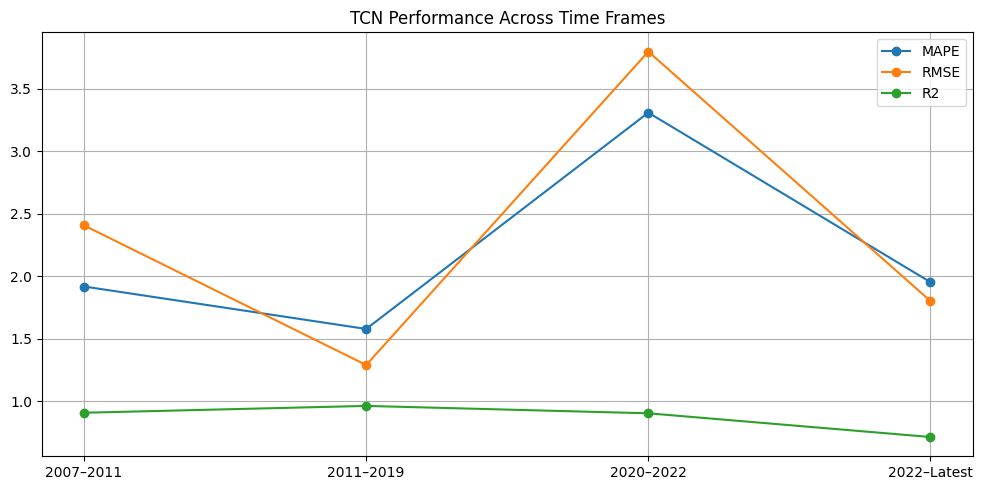

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

from tcn import TCN

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# -------------------------------------------------------
# 1) Load and preprocess dataset
# -------------------------------------------------------
df = pd.read_csv("crude_oil_2007_to_present.csv")

df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace(",", "", regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("Date").reset_index(drop=True)
df = df.fillna(method="ffill").fillna(method="bfill")

df = df[["Date","Open","High","Low","Close"]].dropna().reset_index(drop=True)

# -------------------------------------------------------
# 2) TCN hyperparameters
# -------------------------------------------------------
seq_len = 30
tcn_filters = 64
kernel_size = 3
dropout = 0.05
lr = 0.002
batch_size = 16
epochs = 25

# -------------------------------------------------------
# 3) Helpers
# -------------------------------------------------------
def make_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

def build_tcn_model(seq_len, n_features, output_dim):
    model = Sequential([
        TCN(
            nb_filters=tcn_filters,
            kernel_size=kernel_size,
            dilations=[1,2,4,8,16],
            dropout_rate=dropout,
            return_sequences=False,
            activation='relu',
            padding='causal',
            input_shape=(seq_len, n_features)
        ),
        Dense(output_dim)
    ])
    model.compile(optimizer=Adam(lr), loss="mse")
    return model

def evaluate_period(df_period, label):
    if len(df_period) < seq_len * 3:
        print(f"Skipping {label}, not enough data.")
        return None

    X_raw = df_period[["Open","High","Low","Close"]].values
    y_raw = df_period[["High","Low"]].values

    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X_raw)
    y_scaled = scaler_y.fit_transform(y_raw)

    n = len(X_scaled)
    train_end = int(n * 0.80)

    X_train_raw, y_train_raw = X_scaled[:train_end], y_scaled[:train_end]
    X_test_raw,  y_test_raw  = X_scaled[train_end:], y_scaled[train_end:]

    X_train, y_train = make_sequences(X_train_raw, y_train_raw, seq_len)
    X_test,  y_test  = make_sequences(
        np.vstack([X_train_raw[-seq_len:], X_test_raw]),
        np.vstack([y_train_raw[-seq_len:], y_test_raw]),
        seq_len
    )

    model = build_tcn_model(seq_len, X_train.shape[2], y_scaled.shape[1])
    cb = [EarlyStopping(patience=5, restore_best_weights=True)]

    model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cb,
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0)
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

    print(f"\n=== {label} ===")
    print(f"Samples: {len(df_period)} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.3f} | MAPE: {mape:.3f}%")

    return {
        "Time Frame": label,
        "Samples": len(df_period),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

# -------------------------------------------------------
# 4) EXACT SPLITS REQUESTED
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]
df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]
df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]
df_4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df_1),
    ("2011–2019", df_2),
    ("2020–2022", df_3),
    ("2022–Latest", df_4),
]

# -------------------------------------------------------
# 5) Evaluate all splits
# -------------------------------------------------------
results = []
for label, data_part in splits:
    res = evaluate_period(data_part, label)
    if res:
        results.append(res)

results_df = pd.DataFrame(results)
print("\n\n=== FINAL TCN COMPARISON ===")
print(results_df)

# -------------------------------------------------------
# 6) Plot results
# -------------------------------------------------------
plt.figure(figsize=(10,5))
plt.plot(results_df["Time Frame"], results_df["MAPE"], marker="o", label="MAPE")
plt.plot(results_df["Time Frame"], results_df["RMSE"], marker="o", label="RMSE")
plt.plot(results_df["Time Frame"], results_df["R2"], marker="o", label="R2")
plt.grid(True)
plt.legend()
plt.title("TCN Performance Across Time Frames")
plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, random
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# -------------------------------------------------------
# 1) Load and clean data
# -------------------------------------------------------
df = pd.read_csv("crude_oil_2007_to_present.csv")
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace(",","",regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("Date").reset_index(drop=True)
df = df.fillna(method="ffill").fillna(method="bfill")
df = df[["Date","Open","High","Low","Close"]].dropna().reset_index(drop=True)

# -------------------------------------------------------
# 2) Time splits (your exact segmentation)
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]                      # 2007–2011
df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]  # 2011–2019
df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)] # 2020–2022
df_4 = df[df["Date"].dt.year > 2022]                      # 2022–Latest

splits = [
    ("ConvLSTM", "2007–2011", df_1),
    ("ConvLSTM", "2011–2019", df_2),
    ("ConvLSTM", "2020–2022", df_3),
    ("ConvLSTM", "2022–Latest", df_4),

    ("CatBoost", "2007–2011", df_1),
    ("CatBoost", "2011–2019", df_2),
    ("CatBoost", "2020–2022", df_3),
    ("CatBoost", "2022–Latest", df_4),
]

# -------------------------------------------------------
# 3) Helper functions
# -------------------------------------------------------
seq_len = 30

def make_sequences_convLSTM(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        frame = X[i-seq_len:i]
        frame = frame.reshape(seq_len, 1, X.shape[1], 1)  # (time, height=1, channels, depth=1)
        Xs.append(frame)
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

def make_sequences_simple(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

# ConvLSTM model
def build_convlstm(n_features):
    model = Sequential([
        ConvLSTM2D(
            filters=32,
            kernel_size=(1,3),
            strides=(1,1),
            padding="same",
            return_sequences=False,
            activation="relu",
            input_shape=(seq_len, 1, n_features, 1)
        ),
        Flatten(),
        Dense(64, activation="relu"),
        Dense(2)
    ])
    model.compile(optimizer=Adam(0.002), loss="mse")
    return model

def evaluate_model(df_period, model_type):
    if len(df_period) < seq_len * 3:
        print(f"Skipping — too small")
        return None

    X_raw = df_period[["Open","High","Low","Close"]].values
    y_raw = df_period[["High","Low"]].values

    # scale
    sx = StandardScaler()
    sy = StandardScaler()
    X_scaled = sx.fit_transform(X_raw)
    y_scaled = sy.fit_transform(y_raw)

    # 80/20 split
    n = len(X_scaled)
    train_end = int(n * 0.80)

    X_train_raw, y_train_raw = X_scaled[:train_end], y_scaled[:train_end]
    X_test_raw,  y_test_raw  = X_scaled[train_end:], y_scaled[train_end:]

    # sequence generation
    if model_type == "ConvLSTM":
        X_train, y_train = make_sequences_convLSTM(X_train_raw, y_train_raw, seq_len)
        X_test,  y_test  = make_sequences_convLSTM(
            np.vstack([X_train_raw[-seq_len:], X_test_raw]),
            np.vstack([y_train_raw[-seq_len:], y_test_raw]),
            seq_len
        )
    else:
        X_train, y_train = make_sequences_simple(X_train_raw, y_train_raw, seq_len)
        X_test,  y_test  = make_sequences_simple(
            np.vstack([X_train_raw[-seq_len:], X_test_raw]),
            np.vstack([y_train_raw[-seq_len:], y_test_raw]),
            seq_len
        )
    
    # --------------------
    # Train ConvLSTM
    # --------------------
    if model_type == "ConvLSTM":
        model = build_convlstm(n_features=X_train.shape[3])
        cb = [EarlyStopping(patience=5, restore_best_weights=True)]
        model.fit(
            X_train, y_train,
            validation_split=0.1,
            epochs=20,
            batch_size=16,
            callbacks=cb,
            verbose=0
        )
        y_pred_scaled = model.predict(X_test, verbose=0)

    # --------------------
    # Train CatBoost
    # --------------------
    if model_type == "CatBoost":
        # catboost takes flattened past window
        X_train_cb = X_train.reshape(X_train.shape[0], -1)
        X_test_cb  = X_test.reshape(X_test.shape[0], -1)

        model_h = CatBoostRegressor(
            depth=6,
            learning_rate=0.03,
            iterations=500,
            loss_function="RMSE",
            verbose=False
        )
        model_l = CatBoostRegressor(
            depth=6,
            learning_rate=0.03,
            iterations=500,
            loss_function="RMSE",
            verbose=False
        )

        # High target
        model_h.fit(X_train_cb, y_train[:,0])
        model_l.fit(X_train_cb, y_train[:,1])

        pred_h = model_h.predict(X_test_cb)
        pred_l = model_l.predict(X_test_cb)

        y_pred_scaled = np.column_stack([pred_h, pred_l])

    # inverse scaling
    y_pred = sy.inverse_transform(y_pred_scaled)
    y_true = sy.inverse_transform(y_test)

    # metrics
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

    return mae, rmse, r2, mape

# -------------------------------------------------------
# 4) Run evaluation
# -------------------------------------------------------
results = []

for model_type, label, data_part in splits:
    print(f"\n=== {model_type} | {label} ===")
    r = evaluate_model(data_part, model_type)
    if r:
        mae, rmse, r2, mape = r
        print(f"MAE={mae:.3f} RMSE={rmse:.3f} R2={r2:.3f} MAPE={mape:.3f}%")
        results.append([model_type, label, mae, rmse, r2, mape])

results_df = pd.DataFrame(results, columns=["Model","Time Frame","MAE","RMSE","R2","MAPE"])
print("\n\n=== FINAL RESULTS ===")
print(results_df)



=== ConvLSTM | 2007–2011 ===
MAE=1.470 RMSE=1.921 R2=0.943 MAPE=1.570%

=== ConvLSTM | 2011–2019 ===
MAE=0.781 RMSE=1.047 R2=0.977 MAPE=1.307%

=== ConvLSTM | 2020–2022 ===
MAE=3.495 RMSE=4.879 R2=0.847 MAPE=3.663%

=== ConvLSTM | 2022–Latest ===
MAE=5.472 RMSE=7.007 R2=-3.288 MAPE=8.630%

=== CatBoost | 2007–2011 ===
MAE=2.113 RMSE=2.870 R2=0.872 MAPE=2.241%

=== CatBoost | 2011–2019 ===
MAE=1.302 RMSE=1.774 R2=0.933 MAPE=2.135%

=== CatBoost | 2020–2022 ===
MAE=6.925 RMSE=8.258 R2=0.560 MAPE=7.849%

=== CatBoost | 2022–Latest ===
MAE=2.598 RMSE=3.320 R2=0.049 MAPE=4.092%


=== FINAL RESULTS ===
      Model   Time Frame       MAE      RMSE        R2      MAPE
0  ConvLSTM    2007–2011  1.469949  1.920857  0.942517  1.569970
1  ConvLSTM    2011–2019  0.780595  1.047417  0.976803  1.307369
2  ConvLSTM    2020–2022  3.494785  4.878780  0.847494  3.663205
3  ConvLSTM  2022–Latest  5.471826  7.006503 -3.287531  8.629998
4  CatBoost    2007–2011  2.112622  2.870200  0.871539  2.241271
5  Ca

In [1]:
import numpy as np
import pandas as pd
import warnings, random
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)

# -------------------------------------------------------
# 1) Load & clean data
# -------------------------------------------------------
df=pd.read_csv("gold_2007_to_present.csv")
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(",","",regex=False), errors="coerce")

df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")
df = df[["Date","Close"]].dropna().reset_index(drop=True)

# -------------------------------------------------------
# 2) Time splits (your exact segments)
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]
df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]
df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]
df_4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df_1),
    ("2011–2019", df_2),
    ("2020–2022", df_3),
    ("2022–Latest", df_4)
]

# -------------------------------------------------------
# 3) Forecasting Models
# -------------------------------------------------------
def sarima_forecast(train, test):
    model = SARIMAX(train, 
                    order=(2,1,2), 
                    seasonal_order=(1,1,1,12),
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    fit = model.fit(disp=False)
    pred = fit.forecast(len(test))
    return np.array(pred)

def hwes_forecast(train, test):
    model = ExponentialSmoothing(train,
                                 trend="add",
                                 seasonal="add",
                                 seasonal_periods=12)
    fit = model.fit()
    pred = fit.forecast(len(test))
    return np.array(pred)

def holt_forecast(train, test):
    model = Holt(train)
    fit = model.fit()
    return np.array(fit.forecast(len(test)))

def ses_forecast(train, test):
    model = SimpleExpSmoothing(train)
    fit = model.fit()
    return np.array(fit.forecast(len(test)))

def naive_forecast(train, test):
    return np.repeat(train.iloc[-1], len(test))

def seasonal_naive(train, test):
    m = 12
    return train.iloc[-m:].values.tolist() * (len(test) // m + 1)
    
def moving_average(train, test, window=5):
    return np.repeat(train.rolling(window).mean().iloc[-1], len(test))

# -------------------------------------------------------
# 4) Evaluate all models
# -------------------------------------------------------
def evaluate(true, pred):
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    mape = np.mean(np.abs((true - pred) / (true + 1e-8))) * 100
    r2 = r2_score(true, pred)
    return mae, rmse, mape, r2

results = []

models = {
    "SARIMA": sarima_forecast,
    "HWES": hwes_forecast,
    "Holt Trend": holt_forecast,
    "SES": ses_forecast,
    "Naive": naive_forecast,
    "Seasonal Naive": seasonal_naive,
    "Moving Average": moving_average
}

# -------------------------------------------------------
# 5) Run experiments
# -------------------------------------------------------
for label, df_part in splits:

    df_part = df_part.copy()
    df_part.index = pd.to_datetime(df_part["Date"])

    if len(df_part) < 60:
        continue

    # 80% train / 20% test
    n = len(df_part)
    train = df_part["Close"].iloc[:int(n*0.8)]
    test  = df_part["Close"].iloc[int(n*0.8):]

    print(f"\n=== Time Frame: {label} ===")

    for mname, mfunc in models.items():
        try:
            pred = mfunc(train, test)
            pred = pred[:len(test)]

            mae, rmse, mape, r2 = evaluate(test.values, pred)

            print(f"{mname}: MAE={mae:.2f} RMSE={rmse:.2f} MAPE={mape:.2f}% R2={r2:.3f}")

            results.append([label, mname, mae, rmse, mape, r2])
        except:
            print(f"{mname}: FAILED")
            continue

# -------------------------------------------------------
# 6) Final Comparison Table
# -------------------------------------------------------
results_df = pd.DataFrame(results, columns=["Time Frame","Model","MAE","RMSE","MAPE","R2"])
print("\n\n=== FINAL COMPARISON ===")
print(results_df)



=== Time Frame: 2007–2011 ===
SARIMA: MAE=90.96 RMSE=124.41 MAPE=5.45% R2=0.286
HWES: MAE=91.06 RMSE=124.60 MAPE=5.45% R2=0.283
Holt Trend: MAE=67.06 RMSE=84.66 MAPE=4.24% R2=0.669
SES: MAE=178.18 RMSE=221.81 MAPE=10.68% R2=-1.271
Naive: MAE=178.18 RMSE=221.81 MAPE=10.68% R2=-1.271
Seasonal Naive: MAE=189.10 RMSE=233.65 MAPE=11.34% R2=-1.520
Moving Average: MAE=184.16 RMSE=228.12 MAPE=11.04% R2=-1.402

=== Time Frame: 2011–2019 ===
SARIMA: MAE=92.81 RMSE=119.05 MAPE=6.70% R2=-0.180
HWES: MAE=110.93 RMSE=145.36 MAPE=7.91% R2=-0.759
Holt Trend: MAE=127.80 RMSE=167.14 MAPE=9.08% R2=-1.325
SES: MAE=90.00 RMSE=113.26 MAPE=6.53% R2=-0.068
Naive: MAE=90.00 RMSE=113.25 MAPE=6.53% R2=-0.067
Seasonal Naive: MAE=90.27 RMSE=114.94 MAPE=6.53% R2=-0.099
Moving Average: MAE=89.54 RMSE=115.41 MAPE=6.46% R2=-0.109

=== Time Frame: 2020–2022 ===
SARIMA: MAE=139.09 RMSE=155.36 MAPE=8.12% R2=-4.904
HWES: MAE=164.95 RMSE=181.51 MAPE=9.62% R2=-7.059
Holt Trend: MAE=75.86 RMSE=91.09 MAPE=4.45% R2=-1.030
SES

In [2]:
import numpy as np
import pandas as pd
import warnings, random
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt
from arch.bootstrap import MovingBlockBootstrap

warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)

# -------------------------------------------------------
# 1) LOAD & CLEAN DATA
# -------------------------------------------------------
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col].astype(str).replace(",", "", regex=True), errors="coerce")

df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")
df = df[["Date", "Close"]].dropna().reset_index(drop=True)

# -------------------------------------------------------
# 2) TIME SPLITS
# -------------------------------------------------------
df_1 = df[df["Date"].dt.year <= 2011]
df_2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]
df_3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]
df_4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df_1),
    ("2011–2019", df_2),
    ("2020–2022", df_3),
    ("2022–Latest", df_4)
]

# -------------------------------------------------------
# 3) FORECASTING / FITTING HELPERS
# Each function returns: (fitted_model_or_placeholder, forecast_array, in_sample_pred_for_train)
# in_sample_pred_for_train is used for stacking meta-learner (length == len(train))
# -------------------------------------------------------
def fit_sarima(train):
    model = SARIMAX(train, order=(2,1,2), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fit = model.fit(disp=False)
    forecast = fit.forecast(steps=len(train) if False else None)  # placeholder (we will call forecast outside)
    # in-sample fittedvalues aligned with train index
    in_sample = fit.predict(start=train.index[0], end=train.index[-1])
    return fit, in_sample

def sarima_forecast(fit, steps):
    return fit.forecast(steps=steps).values

def fit_hwes(train):
    fit = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
    in_sample = fit.fittedvalues
    return fit, in_sample

def hwes_forecast(fit, steps):
    return fit.forecast(steps).values

def fit_holt(train):
    fit = Holt(train).fit()
    in_sample = fit.fittedvalues
    return fit, in_sample

def holt_forecast(fit, steps):
    return fit.forecast(steps).values

def fit_ses(train):
    fit = SimpleExpSmoothing(train).fit()
    in_sample = fit.fittedvalues
    return fit, in_sample

def ses_forecast(fit, steps):
    return fit.forecast(steps).values

def naive_forecast(train, steps):
    return np.repeat(train.iloc[-1], steps)

def seasonal_naive_forecast(train, steps, m=12):
    if len(train) < m:
        return np.repeat(train.iloc[-1], steps)
    vals = train.iloc[-m:].values.tolist()
    rep = (steps // m) + 2
    return (vals * rep)[:steps]

def moving_avg_forecast(train, steps, window=5):
    if len(train) < window:
        ma = train.mean()
    else:
        ma = train.rolling(window).mean().iloc[-1]
    return np.repeat(ma, steps)

# -------------------------------------------------------
# 4) DIEBOLD–MARIANO TEST (fixed)
# -------------------------------------------------------
def diebold_mariano(errors_1, errors_2, block_size=5, boot_samples=1000):
    """
    Diebold-Mariano test using moving block bootstrap to estimate variance of loss differential.
    errors_1, errors_2: arrays of forecast errors (actual - forecast) of equal length
    Returns: DM_statistic, two-sided p-value (bootstrap)
    """
    e1 = np.asarray(errors_1)
    e2 = np.asarray(errors_2)
    if len(e1) != len(e2):
        raise ValueError("errors_1 and errors_2 must have same length")

    # squared error differential (loss differential)
    d = (e1 ** 2) - (e2 ** 2)
    mean_d = np.mean(d)

    # bootstrap on d using MovingBlockBootstrap
    bs = MovingBlockBootstrap(block_size, d)  # correct usage: first arg block_size, then arrays
    boot_means = []
    for sample in bs.bootstrap(boot_samples):
        # sample is tuple of arrays corresponding to each input series; we passed only d so sample[0] is array
        boot_sample = sample[0]
        boot_means.append(np.mean(boot_sample))

    boot_means = np.array(boot_means)
    std_boot = np.std(boot_means, ddof=1)
    if std_boot == 0:
        # no variability in bootstrap distribution: return DM=0, p=1
        return 0.0, 1.0

    DM_stat = mean_d / std_boot

    # p-value: proportion of bootstrap means as or more extreme than observed mean_d (two-sided)
    p_val = np.mean(np.abs(boot_means) >= np.abs(mean_d))
    p_val = max(min(p_val, 1.0), 0.0)  # clamp

    return DM_stat, p_val

# -------------------------------------------------------
# 5) EVALUATION + STACKING MODEL (fixed stacking)
# -------------------------------------------------------
results = []
dm_results = []

def evaluate_period(df_part, label):
    global results, dm_results

    df_part = df_part.copy()
    df_part["Date"] = pd.to_datetime(df_part["Date"])
    df_part = df_part.sort_values("Date").reset_index(drop=True)
    df_part = df_part.set_index("Date", drop=False)

    n = len(df_part)
    if n < 80:
        print("Skipping", label, "- not enough data (n={})".format(n))
        return

    # Use last 20% as test (preserves temporal order)
    split_idx = int(n * 0.8)
    train = df_part["Close"].iloc[:split_idx]
    test = df_part["Close"].iloc[split_idx:]

    steps = len(test)

    # --------------- fit base models and obtain in-sample predictions ---------------
    fitted_models = {}
    in_sample_preds = {}

    # SARIMA
    try:
        sar_fit, sar_in = fit_sarima(train)
        fitted_models["SARIMA"] = sar_fit
        in_sample_preds["SARIMA"] = sar_in.values
    except Exception as e:
        print("SARIMA fit failed for", label, ":", e)

    # HWES
    try:
        hw_fit, hw_in = fit_hwes(train)
        fitted_models["HWES"] = hw_fit
        in_sample_preds["HWES"] = hw_in.values
    except Exception as e:
        print("HWES fit failed for", label, ":", e)

    # Holt
    try:
        holt_fit, holt_in = fit_holt(train)
        fitted_models["Holt"] = holt_fit
        in_sample_preds["Holt"] = holt_in.values
    except Exception as e:
        print("Holt fit failed for", label, ":", e)

    # SES
    try:
        ses_fit, ses_in = fit_ses(train)
        fitted_models["SES"] = ses_fit
        in_sample_preds["SES"] = ses_in.values
    except Exception as e:
        print("SES fit failed for", label, ":", e)

    # Naive/Seasonal/MovingAvg: create in-sample series for train length
    in_sample_preds["Naive"] = np.repeat(train.iloc[-1], len(train))
    in_sample_preds["Seasonal Naive"] = (train.iloc[-12:].values.tolist() * ((len(train)//12)+2))[:len(train)] if len(train) >= 1 else np.repeat(train.iloc[-1], len(train))
    in_sample_preds["MovingAvg"] = np.repeat(train.rolling(5).mean().iloc[-1] if len(train)>=5 else train.mean(), len(train))

    # --------------- produce forecasts for test ---------------
    forecasts = {}

    # SARIMA forecast
    if "SARIMA" in fitted_models:
        try:
            forecasts["SARIMA"] = sarima_forecast(fitted_models["SARIMA"], steps)
        except Exception as e:
            print("SARIMA forecast failed for", label, ":", e)
            forecasts["SARIMA"] = np.repeat(train.iloc[-1], steps)

    # HWES forecast
    if "HWES" in fitted_models:
        try:
            forecasts["HWES"] = hwes_forecast(fitted_models["HWES"], steps)
        except Exception as e:
            print("HWES forecast failed for", label, ":", e)
            forecasts["HWES"] = np.repeat(train.mean(), steps)

    # Holt forecast
    if "Holt" in fitted_models:
        try:
            forecasts["Holt"] = holt_forecast(fitted_models["Holt"], steps)
        except Exception as e:
            print("Holt forecast failed for", label, ":", e)
            forecasts["Holt"] = np.repeat(train.mean(), steps)

    # SES forecast
    if "SES" in fitted_models:
        try:
            forecasts["SES"] = ses_forecast(fitted_models["SES"], steps)
        except Exception as e:
            print("SES forecast failed for", label, ":", e)
            forecasts["SES"] = np.repeat(train.mean(), steps)

    # Naive / Seasonal Naive / MovingAvg
    forecasts["Naive"] = naive_forecast(train, steps)
    forecasts["Seasonal Naive"] = seasonal_naive_forecast(train, steps)
    forecasts["MovingAvg"] = moving_avg_forecast(train, steps)

    # --------------- Stacking: train meta on train in-sample preds ---------------
    # Build X_train_meta from in_sample_preds (columns must align)
    base_names = list(in_sample_preds.keys())
    X_meta_train = np.column_stack([in_sample_preds[name] for name in base_names])
    y_meta_train = train.values

    # Fit linear regression meta-learner
    meta = LinearRegression()
    try:
        meta.fit(X_meta_train, y_meta_train)
    except Exception as e:
        print("Meta learner fit failed for", label, ":", e)
        meta = None

    # Build X_test_meta from base forecasts (use same order base_names)
    X_meta_test = np.column_stack([forecasts.get(name, np.repeat(train.mean(), steps)) for name in base_names])

    if meta is not None:
        try:
            stacking_pred = meta.predict(X_meta_test)
        except Exception as e:
            print("Meta predict failed for", label, ":", e)
            stacking_pred = np.repeat(train.mean(), steps)
    else:
        stacking_pred = np.repeat(train.mean(), steps)

    forecasts["Stacking"] = stacking_pred

    # --------------- Compute metrics ---------------
    for name, y_pred in forecasts.items():
        mae = mean_absolute_error(test.values, y_pred)
        rmse = np.sqrt(mean_squared_error(test.values, y_pred))
        mape = np.mean(np.abs((test.values - y_pred) / (test.values + 1e-8))) * 100
        r2 = r2_score(test.values, y_pred)
        results.append([label, name, mae, rmse, mape, r2])

    # --------------- Diebold-Mariano: SARIMA vs others ---------------
    if "SARIMA" not in forecasts:
        print("Skipping DM for", label, "- SARIMA forecast not available")
        return

    sarima_err = test.values - forecasts["SARIMA"]

    for name, y_pred in forecasts.items():
        if name == "SARIMA":
            continue
        err2 = test.values - y_pred
        try:
            DM_stat, p_val = diebold_mariano(sarima_err, err2, block_size=5, boot_samples=1000)
        except Exception as e:
            print("DM test failed for", label, "vs", name, ":", e)
            DM_stat, p_val = np.nan, np.nan
        dm_results.append([label, "SARIMA", name, DM_stat, p_val])

# -------------------------------------------------------
# RUN ALL PERIODS
# -------------------------------------------------------
for label, df_part in splits:
    evaluate_period(df_part, label)

final_results = pd.DataFrame(results, columns=["Time", "Model", "MAE", "RMSE", "MAPE", "R²"])
dm_df = pd.DataFrame(dm_results, columns=["Time", "Model_A", "Model_B", "DM_stat", "p_value"])

print("\n=== FORECASTING RESULTS ===")
print(final_results)

print("\n=== DIEBOLD–MARIANO TEST RESULTS ===")
print(dm_df)



=== FORECASTING RESULTS ===
           Time           Model         MAE        RMSE       MAPE        R²
0     2007–2011          SARIMA   90.960210  124.412436   5.449512  0.285559
1     2007–2011            HWES   91.062214  124.596678   5.453968  0.283441
2     2007–2011            Holt   67.064760   84.659450   4.236176  0.669181
3     2007–2011             SES  178.175909  221.812502  10.682065 -1.270968
4     2007–2011           Naive  178.175909  221.812502  10.682065 -1.270968
5     2007–2011  Seasonal Naive  189.097240  233.652780  11.344395 -1.519886
6     2007–2011       MovingAvg  184.155428  228.118822  11.044102 -1.401935
7     2007–2011        Stacking  128.786809  166.627293   7.701316 -0.281537
8     2011–2019          SARIMA   92.811781  119.053163   6.701083 -0.179679
9     2011–2019            HWES  110.930720  145.360241   7.912829 -0.758625
10    2011–2019            Holt  127.795105  167.143932   9.082194 -1.325216
11    2011–2019             SES   89.998091  11